# Workshop -1 Adding Sunglasses to Your Passport Photo Using OpenCV

# NAME: DEVASURYA M 

# REG: 212225230048

In [1]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

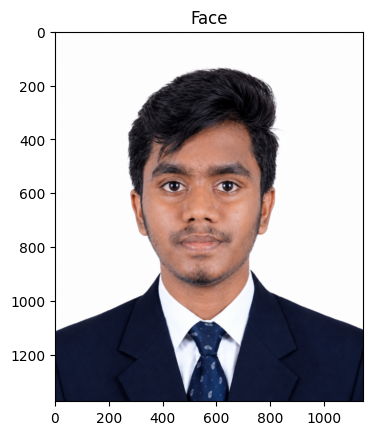

In [2]:
# Load the Face Image
faceImage = cv2.imread('sunimg.png')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [8]:
faceImage.shape

(1374, 1145, 3)

In [9]:
#resized_faceImage.shape
faceImage.shape

(1374, 1145, 3)

Text(0.5, 1.0, 'glassPNG')

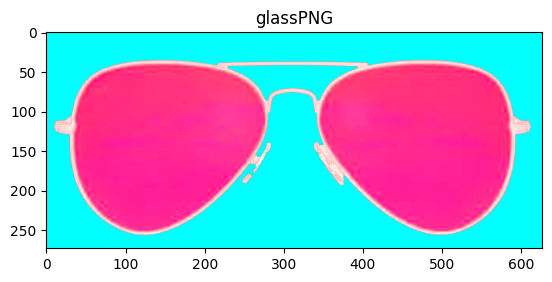

In [10]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('sunglass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

In [11]:
# Keep the original sunglasses dimensions here.
# The fitting cell below resizes the glasses proportionally.
if glassPNG is None:
    raise FileNotFoundError("Could not load sunglass.png. Keep it in the notebook folder.")
print("Original sunglasses dimensions:", glassPNG.shape)


Original sunglasses dimensions: (273, 627, 4)


In [12]:
# Separate the BGR color and transparency (alpha) channels.
if glassPNG.ndim == 3 and glassPNG.shape[2] == 4:
    glassBGR = glassPNG[:, :, :3]
    glassAlpha = glassPNG[:, :, 3]
elif glassPNG.ndim == 3 and glassPNG.shape[2] == 3:
    glassBGR = glassPNG
    # Fallback for a PNG without transparency.
    gray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)
    glassAlpha = np.where(gray > 5, 255, 0).astype(np.uint8)
else:
    raise ValueError("sunglass.png must be a 3-channel or 4-channel image.")


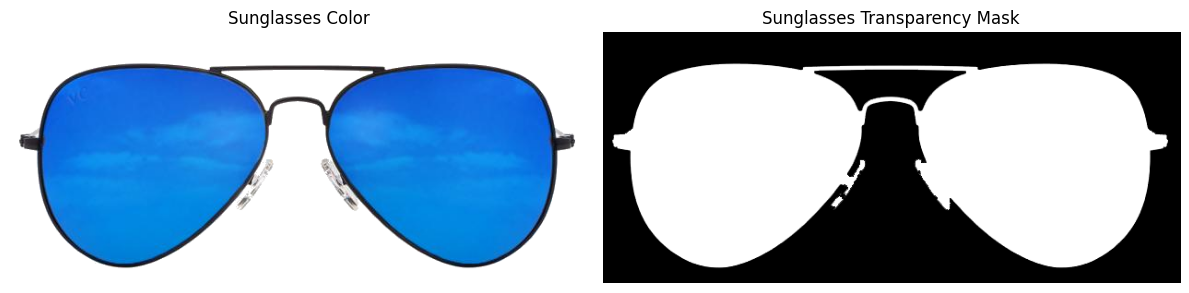

In [13]:
# Display the sunglasses color and alpha (transparency) channels.
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(glassBGR, cv2.COLOR_BGR2RGB))
plt.title("Sunglasses Color")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(glassAlpha, cmap="gray")
plt.title("Sunglasses Transparency Mask")
plt.axis("off")

plt.tight_layout()
plt.show()


Eye detection: successful
Face dimensions: 1145 x 1374
Fitted glasses dimensions: 489 x 180
Glasses top-left coordinate: (297, 501)


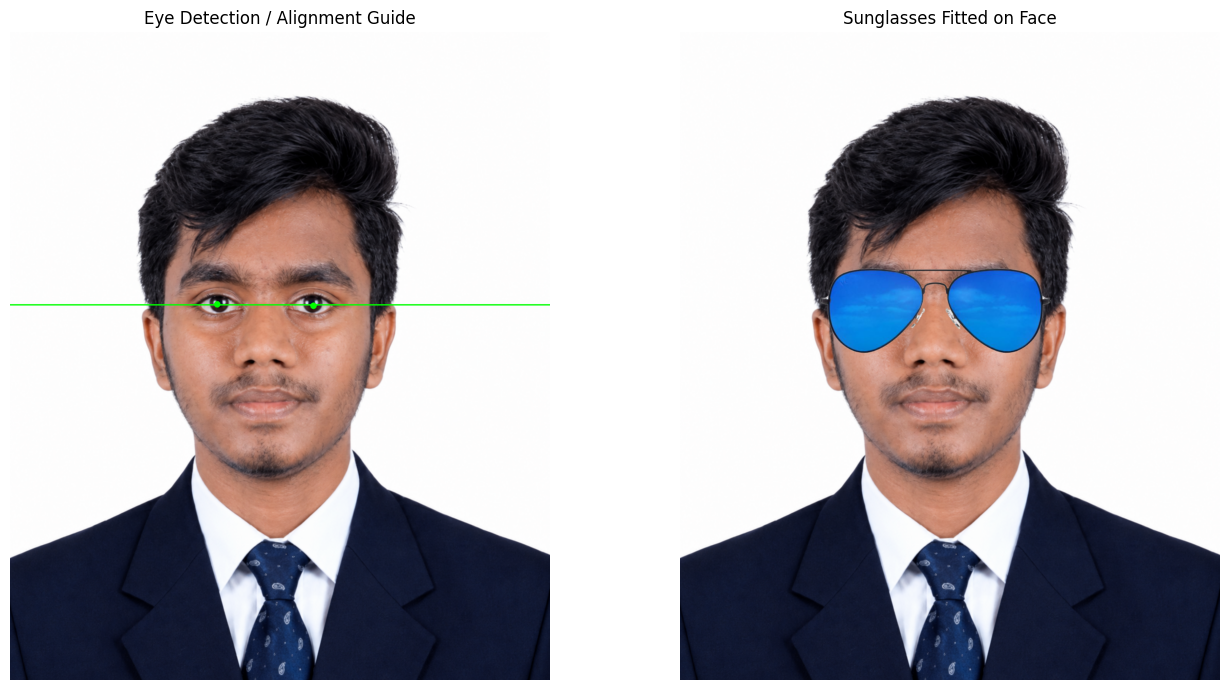

In [14]:
# Automatically locate both eyes and fit the sunglasses around them.
# The code falls back to adjustable face-relative coordinates if eye detection fails.

if faceImage is None:
    raise FileNotFoundError("Could not load sunimg.png. Keep it in the notebook folder.")

face_h, face_w = faceImage.shape[:2]

# ---------- MANUAL FALLBACK CONTROLS ----------
# Used only if OpenCV cannot reliably detect both eyes.
MANUAL_CENTER_X_RATIO = 0.50
MANUAL_EYE_LINE_Y_RATIO = 0.39
MANUAL_GLASS_WIDTH_RATIO = 0.46
# Fine adjustments after automatic/manual placement:
SHIFT_X = 0       # positive = right, negative = left
SHIFT_Y = 0       # positive = down, negative = up
# ---------------------------------------------

# Keep the sunglasses' original aspect ratio.
glass_h0, glass_w0 = glassBGR.shape[:2]
aspect_ratio = glass_w0 / glass_h0

# Try to detect a frontal face and a pair of eyes.
gray_face = cv2.cvtColor(faceImage, cv2.COLOR_BGR2GRAY)
face_cascade_path = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
eye_cascade_path = cv2.data.haarcascades + "haarcascade_eye_tree_eyeglasses.xml"

face_cascade = cv2.CascadeClassifier(face_cascade_path)
eye_cascade = cv2.CascadeClassifier(eye_cascade_path)

detected_pair = None
faces = face_cascade.detectMultiScale(
    gray_face, scaleFactor=1.1, minNeighbors=5, minSize=(80, 80)
)

if len(faces) > 0:
    # Use the largest detected face.
    fx, fy, fw, fh = max(faces, key=lambda box: box[2] * box[3])

    # Search for eyes only in the upper part of the face.
    upper_face = gray_face[fy:fy + int(fh * 0.68), fx:fx + fw]
    eyes = eye_cascade.detectMultiScale(
        upper_face, scaleFactor=1.1, minNeighbors=6, minSize=(20, 15)
    )

    # Keep plausible eye candidates and choose the pair with the largest
    # horizontal separation, which usually corresponds to the two eyes.
    candidates = []
    for ex, ey, ew, eh in eyes:
        center_x = fx + ex + ew / 2
        center_y = fy + ey + eh / 2
        if 0.12 * fw < ex + ew / 2 < 0.88 * fw:
            candidates.append((center_x, center_y, ew, eh))

    if len(candidates) >= 2:
        candidates.sort(key=lambda item: item[0])
        # Choose a pair with similar vertical positions and useful separation.
        pairs = []
        for i in range(len(candidates)):
            for j in range(i + 1, len(candidates)):
                left_eye, right_eye = candidates[i], candidates[j]
                separation = right_eye[0] - left_eye[0]
                vertical_difference = abs(right_eye[1] - left_eye[1])
                if separation > 0.18 * fw and vertical_difference < 0.16 * fh:
                    score = separation - 1.5 * vertical_difference
                    pairs.append((score, left_eye, right_eye))
        if pairs:
            _, left_eye, right_eye = max(pairs, key=lambda item: item[0])
            detected_pair = (left_eye, right_eye)

if detected_pair is not None:
    left_eye, right_eye = detected_pair
    eye_distance = right_eye[0] - left_eye[0]
    center_x = (left_eye[0] + right_eye[0]) / 2

    # A frame width around 2.5 times the eye-center distance usually
    # covers both eyes and the bridge without stretching the PNG.
    target_w = int(eye_distance * 2.50)
    eye_line_y = (left_eye[1] + right_eye[1]) / 2
    print("Eye detection: successful")
else:
    # Fallback for images where Haar eye detection is unavailable/uncertain.
    center_x = face_w * MANUAL_CENTER_X_RATIO
    eye_line_y = face_h * MANUAL_EYE_LINE_Y_RATIO
    target_w = int(face_w * MANUAL_GLASS_WIDTH_RATIO)
    print("Eye detection: not reliable; using manual fallback controls.")

target_w = max(1, min(target_w, int(face_w * 0.90)))
target_h = max(1, int(target_w / aspect_ratio))

# Resize color and alpha with identical dimensions.
interpolation = cv2.INTER_AREA if target_w < glass_w0 else cv2.INTER_CUBIC
resized_glass = cv2.resize(glassBGR, (target_w, target_h), interpolation=interpolation)
resized_alpha = cv2.resize(glassAlpha, (target_w, target_h), interpolation=interpolation)

# Crop transparent borders so placement uses the visible frame boundaries.
visible = cv2.findNonZero((resized_alpha > 8).astype(np.uint8))
if visible is not None:
    bx, by, bw, bh = cv2.boundingRect(visible)
    resized_glass = resized_glass[by:by + bh, bx:bx + bw]
    resized_alpha = resized_alpha[by:by + bh, bx:bx + bw]

target_h, target_w = resized_alpha.shape[:2]

# Align the bridge near the midpoint between the eyes.
x1 = int(round(center_x - target_w / 2 + SHIFT_X))
# Place the glasses so their upper frame sits slightly above the eye line.
y1 = int(round(eye_line_y - target_h * 0.43 + SHIFT_Y))
x2, y2 = x1 + target_w, y1 + target_h

# Clip overlay coordinates safely to the image boundaries.
dst_x1, dst_y1 = max(0, x1), max(0, y1)
dst_x2, dst_y2 = min(face_w, x2), min(face_h, y2)

if dst_x1 >= dst_x2 or dst_y1 >= dst_y2:
    raise ValueError("The glasses are outside the face image. Adjust SHIFT_X or SHIFT_Y.")

src_x1, src_y1 = dst_x1 - x1, dst_y1 - y1
src_x2 = src_x1 + (dst_x2 - dst_x1)
src_y2 = src_y1 + (dst_y2 - dst_y1)

faceWithGlasses = faceImage.copy()
roi = faceWithGlasses[dst_y1:dst_y2, dst_x1:dst_x2].astype(np.float32)
glass_roi = resized_glass[src_y1:src_y2, src_x1:src_x2].astype(np.float32)
alpha = resized_alpha[src_y1:src_y2, src_x1:src_x2].astype(np.float32) / 255.0
alpha = alpha[:, :, np.newaxis]

# Alpha blending keeps the original face visible through transparent areas.
blended = roi * (1.0 - alpha) + glass_roi * alpha
faceWithGlasses[dst_y1:dst_y2, dst_x1:dst_x2] = np.clip(blended, 0, 255).astype(np.uint8)

print(f"Face dimensions: {face_w} x {face_h}")
print(f"Fitted glasses dimensions: {target_w} x {target_h}")
print(f"Glasses top-left coordinate: ({x1}, {y1})")

# Show the detected eye line and final placement for easy verification.
preview = faceImage.copy()
if detected_pair is not None:
    for eye in detected_pair:
        cv2.circle(preview, (int(eye[0]), int(eye[1])), 7, (0, 255, 0), -1)
    cv2.line(preview, (0, int(eye_line_y)), (face_w - 1, int(eye_line_y)), (0, 255, 0), 2)

plt.figure(figsize=(14, 7))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.title("Eye Detection / Alignment Guide")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(faceWithGlasses, cv2.COLOR_BGR2RGB))
plt.title("Sunglasses Fitted on Face")
plt.axis("off")
plt.tight_layout()
plt.show()


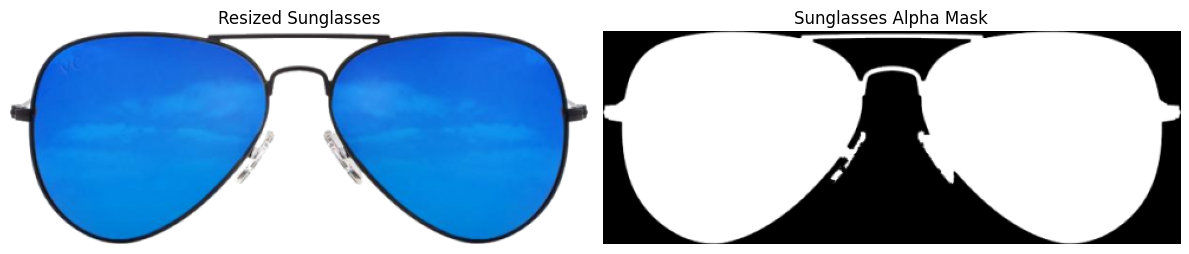

In [15]:
# Display the eye-area overlay and transparency mask for checking.
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(resized_glass, cv2.COLOR_BGR2RGB))
plt.title("Resized Sunglasses")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_alpha, cmap="gray")
plt.title("Sunglasses Alpha Mask")
plt.axis("off")
plt.tight_layout()
plt.show()


In [ ]:
# Compare the original face with the final fitted result.
plt.figure(figsize=(14, 8))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.title("Original Face")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(faceWithGlasses, cv2.COLOR_BGR2RGB))
plt.title("Face with Fitted Sunglasses")
plt.axis("off")

plt.tight_layout()
plt.show()
